# Setup, authentic data, and frozen protocol

This suite implements E0–E4 from the supplied blueprint. Research strategy documents are proposals, not results. No experiment uses generated benchmark examples or mock inference. The dataset is publisher-hosted HotpotQA **fullwiki validation candidate contexts**; this is not retrieval over the entire Wikipedia corpus. Exact response logs authenticate new runs; legacy rescoring cannot authenticate historical inference.

Read `README.md`, then configure `config.json`. Install `requirements.txt` in your chosen notebook environment. API credentials belong in environment variables or the notebook platform's secret store. Do not print them. Use an immutable model/deployment revision and a matching tokenizer commit. There is no universally best model; keep the primary backbone fixed and compare another backbone separately.

The default sample is 300 questions, proportional bridge/comparison strata. BM25 ranks the same candidate pool once per question, retaining six documents. No gold answer or support label selects documents, roles, partitions, routing, crops, or stopping. Gold is used only after prediction for scoring and coverage diagnostics.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd() if (Path.cwd() / 'protocol.py').exists() else Path.cwd() / 'WEBExtension'
if not (ROOT / 'protocol.py').exists():
    raise FileNotFoundError('Launch Jupyter from the project root or WEBExtension folder')
ROOT = ROOT.resolve()
sys.path.insert(0, str(ROOT))
from protocol import load_official, write_json, file_hash
from experiments import load_config, preview, freeze, run
CFG = load_config(ROOT / 'config.json')
EXECUTE = False  # Set True only after configuring your real backend and maximum call budget.
print('Notebook root:', ROOT)
print('Inference enabled:', EXECUTE)


Notebook root: /home/saurab/Documents/projectRLMAIN/WEBExtension
Inference enabled: False


## Download and verify

Data are already included. `download_data.prepare()` can obtain the pinned publisher-hosted parquet when missing. It never invents fallback data. The original CMU download timed out during preparation; this is explicitly recorded. HotpotQA uses CC BY-SA 4.0. Keep the attribution and dataset provenance when distributing results.

In [2]:
from download_data import prepare
if not (ROOT / 'data/hotpot_dev_fullwiki_v1.provenance.json').exists():
    prepare()
rows = load_official()
print('Verified complete validation rows:', len(rows))
print(json.loads((ROOT / 'artifacts/dataset_verification.json').read_text()))

Verified complete validation rows: 7405
{'official_rows': 7405, 'legacy_rows': 100, 'legacy_exact_matches': 100, 'official_provenance': {'source_url': 'https://curtis.ml.cmu.edu/datasets/hotpot/hotpot_dev_fullwiki_v1.json', 'actual_download_url': 'https://huggingface.co/datasets/hotpotqa/hotpot_qa/resolve/1908d6afbbead072334abe2965f91bd2709910ab/fullwiki/validation-00000-of-00001.parquet', 'publisher': 'hotpotqa/hotpot_qa', 'revision': '1908d6afbbead072334abe2965f91bd2709910ab', 'split': 'validation', 'configuration': 'fullwiki', 'source_sha256': '78933c0a31a5f7b420d4effdf4cd4eed573b28c6a3da6179dcf7a02b39e51d03', 'sha256': '103e345973c309cb857a72d8519e1edaa03d50a6611c059bcf5b12f50bcc5909', 'rows': 7405, 'prepared_at_utc': '2026-10-13T17:35:58.334341+00:00', 'license': 'CC BY-SA 4.0', 'transformation': 'parquet to JSON; no text/label modification', 'caveat': 'Original CMU host unavailable at preparation; publisher-hosted pinned mirror used.'}}


## Freeze before inference

`freeze()` binds config, source hashes, dataset hash and ordered question IDs. A changed protocol creates a different run directory. The primary contrast is `(CW−NoComm)_P − (CW−NoComm)_R` in F1 percentage points. Other contrasts are exploratory. E1 includes a same-call self-update control by default; CW versus NoComm alone combines information delivery with additional inference. Run a separate 10–20 question pilot to check invariants and costs, without selecting methods on favorable answers. Never merge pilot scores into the primary sample.

In [3]:
print(json.dumps(preview(CFG), indent=2))
RUN_DIR, sample = freeze(CFG)
print('Frozen sample:', len(sample), 'questions at', RUN_DIR)

{
  "run_dir": "/home/saurab/Documents/projectRLMAIN/WEBExtension/artifacts/run_d90e67a084d95ef3",
  "n_questions": 300,
  "E1_max_new_calls": 7200,
  "E2_standalone_max_calls": 2700,
  "E2_after_E1_new_calls": 0,
  "E3_standalone_max_calls": 1500,
  "E3_after_E1_max_calls": 600,
  "E4_standalone_max_calls": 3600,
  "note": "Upper bounds; E1/E2 identical prompts reuse exact cache. No inference performed."
}
Frozen sample: 300 questions at /home/saurab/Documents/projectRLMAIN/WEBExtension/artifacts/run_d90e67a084d95ef3


In [4]:
from protocol import retrieve, assign_evidence
import pandas as pd
coverage=[]
for row in sample:
    pool=retrieve(row['question'],row['documents'],CFG['top_k'])
    gold=set(map(tuple,row['supporting_facts']))
    available={(d['title'],i) for d in pool for i in range(len(d['sentences']))}
    assigned=assign_evidence(pool,'P',row['id'],CFG['partition_seed'])
    per_node=[{(d['title'],i) for d in a for i in range(len(d['sentences']))} for a in assigned]
    coverage.append({'id':row['id'],'type':row['type'],'all_support_available':gold<=available,
                     'support_recall':len(gold&available)/len(gold),
                     'support_split':gold<=available and not any(gold<=o for o in per_node)})
coverage=pd.DataFrame(coverage)
coverage.to_csv(RUN_DIR/'retrieval_availability.csv',index=False)
display(coverage.groupby('type').agg(n=('id','size'), all_support_available=('all_support_available','mean'),
                                    mean_support_recall=('support_recall','mean'),split_support=('support_split','mean')))
print('These are dataset/retrieval diagnostics, not QA model results.')

,n,all_support_available,mean_support_recall,split_support
type,,,,
bridge,240,0.275000,0.570486,0.229167
comparison,60,0.166667,0.393056,0.116667


These are dataset/retrieval diagnostics, not QA model results.


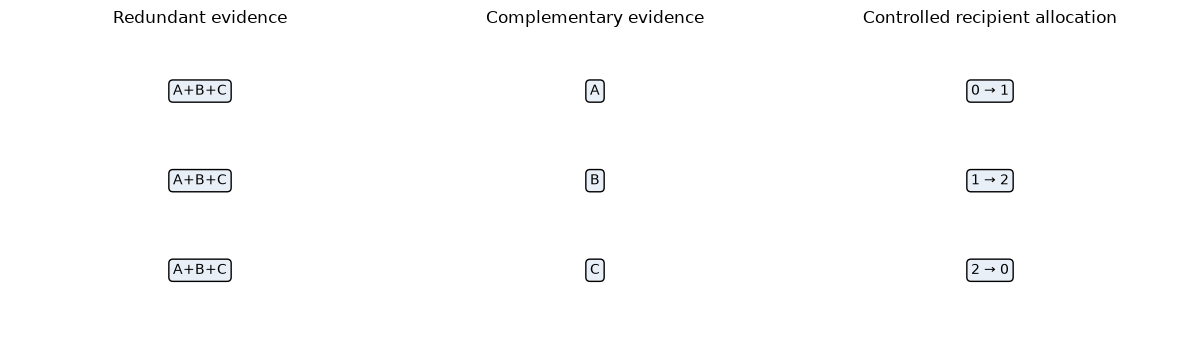

In [5]:
import matplotlib.pyplot as plt
fig, axes=plt.subplots(1,3,figsize=(12,3.5))
for ax,title,labels in zip(axes,['Redundant evidence','Complementary evidence','Controlled recipient allocation'],
                          [['A+B+C']*3,['A','B','C'],['0 → 1','1 → 2','2 → 0']]):
    ax.set_title(title);ax.axis('off')
    for i,label in enumerate(labels):
        ax.text(.5,.8-i*.3,label,ha='center',va='center',bbox=dict(boxstyle='round',facecolor='#e8eff7'))
fig.tight_layout();fig.savefig(ROOT/'artifacts/protocol_diagram.svg');plt.show()

## Pilot rule

For a pilot, copy CFG with `n_questions=10`, `replicate_id="invariant_pilot"`, a confirmed immutable model/tokenizer revision and a sufficient call cap. Run E1, E3 and a short E4. Inspect raw prompts, token usage, invalid citations, exact payload matching and parsing failures before launching 300 questions. If the protocol changes, freeze a new manifest and disclose that change. Temperature zero does not guarantee provider determinism.